¡Hola José! Espero estés bien.

Mi nombre es **Gina Buvoli**. Un gusto conocerte, seré tu revisora en este proyecto.

A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:

Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.

Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierta a responder cualquier duda que tengas.

Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.

---

### Formato de Comentarios

Revisaré cuidadosamente cada implementación en tu notebook para asegurar que cumpla con los requisitos y te daré comentarios de acuerdo al siguiente formato:

<div class="alert alert-block alert-success">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>Éxito ✅</b><br>

¡Excelente trabajo! Esta parte está bien implementada y contribuye significativamente al análisis. Continúa aplicando estas buenas prácticas en futuras secciones.

</div>

<div class="alert alert-block alert-warning">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>Atención ⚠️</b><br>

El código es correcto, pero hay una recomendación de mejora. No bloquea la aprobación, pero vale la pena ajustarlo.

</div>

<div class="alert alert-block alert-danger">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>A resolver 🔴</b><br>

Aquí hay un error que es necesario corregir para aprobar. Por favor revisa este punto antes de volver a enviar.

</div>

---

En cada revisión recibirás un **Comentario General** que resume los aspectos positivos, las áreas de mejora y los próximos pasos.

También puedes responderme copiando el siguiente bloque si tienes alguna duda:

<div class="alert alert-block alert-info">

<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Aquí puedes escribir tu respuesta o pregunta.

</div>

**¡Empecemos!** 🚀

<div class="alert alert-block alert-danger">

<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br>

¡Hola José!<br>

Tu proyecto tiene una buena estructura general: cargas correctamente los tres datasets, exploras sus dimensiones y tipos, identificas los sentinels principales, aplicas segmentaciones por uso y edad y publicaste el proyecto en un repositorio público de GitHub con un <code>README.md</code> completo.<br>

Antes de aprobar necesitamos corregir varios puntos que afectan directamente la calidad y reproducibilidad del análisis:<br>

1. <b>Revisión de nulos.</b> Estás usando <code>isna().count()</code>, que cuenta filas y no valores nulos. Por eso obtienes 4.000 para todas las columnas de <code>users</code> y concluyes que existen “4.000 registros nulos”, lo cual no representa los datos reales.<br>

2. <b>Fechas fuera de rango.</b> El proyecto trabaja con datos hasta 2024, por lo que las 40 fechas de 2026 deben tratarse como inválidas. Sin embargo, usas la fecha actual como límite y esas fechas permanecen en el dataset.<br>

3. <b>Diagnóstico MAR.</b> Los nulos de <code>duration</code> y <code>length</code> dependen del tipo de evento, por lo que corresponden al patrón estructural esperado y deben interpretarse como MAR en este proyecto. En tu conclusión los clasificas como MNAR y además inviertes el significado de las columnas.<br>

4. <b>Métrica de minutos de llamada.</b> En la agregación por usuario estás sumando <code>length</code> y la renombras como <code>cant_minutos_llamada</code>. Para los minutos de llamadas debes agregar <code>duration</code>. Esto altera estadísticas, histogramas, IQR y conclusiones posteriores.<br>

5. <b>Comparación por plan.</b> Los histogramas se construyen sin <code>hue='plan'</code>, por lo que no permiten comparar Básico y Premium como solicita el proyecto.<br>

6. <b>Reproducibilidad.</b> La última celda contiene la URL de GitHub como código Python y genera un <code>SyntaxError</code>. Un <b>Restart & Run All</b> no puede terminar correctamente.<br>

Tu proyecto queda <b>RECHAZADO</b>. 🔴<br>

Para la siguiente iteración te recomiendo corregirlo en este orden:<br>

1. Recalcula los nulos usando métodos que realmente cuenten valores faltantes y calcula también su proporción por columna.<br>
2. Corrige la limpieza de <code>reg_date</code> usando 2024 como límite del proyecto y verifica que queden exactamente 40 fechas inválidas convertidas en <code>NaT</code>.<br>
3. Revisa nuevamente <code>duration</code> y <code>length</code> por <code>type</code> y corrige el diagnóstico MAR.<br>
4. Reconstruye <code>usage_agg</code> usando <code>duration</code> para los minutos de llamada.<br>
5. Realiza nuevamente el <code>left merge</code>, revisa el usuario sin actividad y representa sus métricas de uso de forma coherente antes de segmentar.<br>
6. Recalcula estadísticas, histogramas, boxplots, IQR y conclusiones con las métricas corregidas.<br>
7. En los histogramas usa <code>hue='plan'</code> para comparar Básico y Premium.<br>
8. Actualiza el análisis ejecutivo con las cifras correctas y evita conclusiones que no estén respaldadas por el análisis.<br>
9. Deja el enlace de GitHub en una celda Markdown, no en una celda de código.<br>
10. Finalmente ejecuta <b>Restart & Run All</b> desde cero y confirma que el notebook llega al final sin errores.<br>

Tienes varios componentes ya construidos correctamente; el siguiente paso es asegurar que cada métrica represente la variable correcta y que las conclusiones se basen en esos resultados corregidos.<br>
</div>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)
# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)
# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
La carga y exploración inicial están correctamente realizadas. Importas los datasets, muestras sus primeras filas y revisas dimensiones y tipos de datos con <code>.shape</code> y <code>.info()</code>.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
for col in users.columns:
    print(col)
    print(4000-users[col].count())
    print(users[col].isna().mean()*100, "%")

user_id
0
0.0 %
first_name
0
0.0 %
last_name
0
0.0 %
age
0
0.0 %
city
469
11.725 %
reg_date
0
0.0 %
plan
0
0.0 %
churn_date
3534
88.35 %


In [11]:
# cantidad de nulos para usage
for col in usage.columns:
    print(col)
    print(40000-usage[col].count()) 
    print(usage[col].isna().mean()*100, "%")

id
0
0.0 %
user_id
0
0.0 %
type
0
0.0 %
date
50
0.125 %
duration
22076
55.19 %
length
17896
44.74 %


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.


# En "users" se encuentran 469 valores nulos para "city", y 3534 para "churn_date". Estos corresponden al 11.7% y 88.35%, lo que implica que los valores de la columna "churn_date" no es confiable para su uso en el análisis.
# En "usage" hay 50 (0.125%) para "date", 22076 (55.19%) para "duration" y 17896 (44.74%) para "length". En las columnas con alta proporción de nulos se debe realizar un tratamiento para obtener únicamente las filas que incluyan un valor válido, vamos a ver si esta proporción se torna más favorable al filtrar los registros por fecha para enfocar el ejercicio en registros correspondientes al año 2024.


💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


# Resultados del análisis exploratorio
- La columna `user_id` muestra una distribución simétrica.
- La columna `age` muestra un sesgo a la derecha, además de la existencia de un valor sentinela "-999".

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`presentan la misma cantidad de registros, con la distribución esperada para este tipo de columnas.
- Las columnas "duration" y "length" muestran un sesgo aa la izquierda al analizarse por usos individuales, pero la magnitud de los valores máximos revela la presencia de posibles outliers.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].describe())
    print(users[col].unique())

    

count       3531
unique         7
top       Bogotá
freq         808
Name: city, dtype: object
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
count       4000
unique         2
top       Basico
freq        2595
Name: plan, dtype: object
['Basico' 'Premium']


- La columna `city` incluye 7 categorías, dos de ellas quivalentes entre si, con valores sentinela "?" y "nan". La moda es "Bogotá", con 808 registros. Esta columna presenta 469 registros inválidos además de los sentinels.
- La columna `plan` consiste en 2 categorías normales, la moda es "Basico" con 2595 registros.

In [15]:
# explorar columna categórica de usage
print(usage['type'].describe())
print(usage['type'].unique())
# completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object
['call' 'text']


- La columna `type` contiene 2 categorías, el tipo más común es "text", aunque la distribución no es demasiado sesgada.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors = "coerce")
# completa el código


In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors = "coerce")
# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"].dt.year
users["reg_date"].dt.year.unique()

array([2022, 2026, 2023, 2024])

# COMENTARIO
En `reg_date`, se encuentran fechas de 2022 a 2024 y de 2026, en el contexto del ejercicio el año 2026 no ha transcurrido aún. Debemos clarificar si son entradas erróneas que se pueden corregir o si se pueden eliminar para estabilizar las medidas. También es posible que se analicen sólo relaciones en 2024 para que haya coherencias con los datos en la base "usage".

In [19]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year
usage["date"].dt.year.unique()

array([2024.,   nan])

En `date`, sólo podemos ver fechas del año 2024.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Aquí es necesario corregir la revisión de valores nulos. <code>isna().count()</code> no cuenta cuántos nulos existen; cuenta cuántos registros tiene cada columna. Por eso aparecen 4.000 en todas las columnas de <code>users</code> y 40.000 en todas las de <code>usage</code>.<br><br>
Esto lleva a una conclusión incorrecta de que hay “4.000 registros nulos” equivalentes al 12.5%.<br><br>
Para corregirlo:<br>
1. Obtén la <b>cantidad real de nulos por columna</b>.<br>
2. Calcula la <b>proporción de nulos por columna</b> usando el total de filas de cada dataset como denominador.<br>
3. Reescribe el diagnóstico indicando qué columnas tienen faltantes y qué decisión tomarías en cada caso.<br>
4. Mantén la detección de <code>-999</code> y <code>"?"</code>, que sí está correctamente identificada.<br><br>
Además, en fechas identificas correctamente que 2026 está fuera del rango del proyecto. Esa observación deberá reflejarse después en la limpieza.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users["age"].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)

# Verificar cambios
users['city'].unique()

array(['Medellín', <NA>, 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [22]:
# Marcar fechas futuras como NA para reg_date

users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].describe()) 

print("total registros", users["reg_date"].count())
print("registros con fecha nula", users["reg_date"].isna().sum())

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object
total registros 3960
registros con fecha nula 40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration"].isna().groupby(usage["type"]).mean().sort_values(ascending = False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().groupby(usage["type"]).mean().sort_values(ascending = False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquí y escribe que tu diagnostico de nulos en `duration` y `length`:

Los datos muestran que los nulos para "duration" corresponden con los registros de tipo "call", mientras que los nulos para "length" corresponden a los registros de tipo "text". Esto indica un patrón MNAR, en el que "duration" es la duración de la llamada y "length" es el tamaño del texto, por eso los nulos aparecfen en la columna opuesta y la correspondiente si tiene valores.

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Hay dos correcciones importantes en esta sección.<br><br>
<b>1. Fechas:</b> el proyecto establece que los datos válidos llegan hasta 2024. El criterio de limpieza debe basarse en ese corte, no en la fecha actual. Con <code>pd.Timestamp.today()</code>, las fechas de 2026 ya no se consideran futuras y permanecen en el dataset. Debes marcar como <code>NaT</code> las fechas cuyo año sea posterior a 2024 y verificar que sean 40 casos.<br><br>
<b>2. MAR:</b> tu código muestra que los nulos dependen de <code>type</code>, pero la interpretación escrita está invertida. <code>duration</code> representa duración de llamadas y <code>length</code> longitud de mensajes. La ausencia depende del tipo de evento y, para este proyecto, debe reconocerse como un patrón MAR/estructural y conservarse como nulo.<br><br>
Como mejora adicional, calcula la mediana de <code>age</code> excluyendo primero <code>-999</code>; así evitas que el sentinel influya en el valor utilizado para imputar.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
cant_mensajes = usage["is_text"].sum() #conocer el total de mensajes

usage["is_call"] = (usage["type"] == "call").astype(int)
cant_llamadas = usage["is_call"].sum() #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id", dropna = False).agg({"is_text":"sum", "is_call":"sum", "duration":"sum"}).reset_index()


# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns = {"is_text":"cant_mensajes", "is_call":"cant_llamadas", "duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on = ["user_id"], how = "left")
user_profile["cant_mensajes"] = user_profile["cant_mensajes"].fillna(0)
user_profile["cant_llamadas"] = user_profile["cant_llamadas"].fillna(0)
user_profile["cant_minutos_llamada"] = user_profile["cant_minutos_llamada"].fillna(0)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
num_cols = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[num_cols].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.122250,5.523000,4.477000,23.311225
std,17.690408,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [29]:

# Distribución porcentual del tipo de plan
plan_types = ['Basico', 'Premium']
for plan in plan_types:
    print("Cantidad de usuarios con plan:", plan)
    print(len(user_profile[user_profile["plan"] == plan]))


Cantidad de usuarios con plan: Basico
2595
Cantidad de usuarios con plan: Premium
1405


<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
La agregación por usuario tiene un error conceptual importante: estás sumando <code>length</code> y luego renombras esa columna como <code>cant_minutos_llamada</code>.<br><br>
<code>length</code> corresponde a la longitud de los mensajes, mientras que los minutos de llamada deben calcularse a partir de <code>duration</code>. Por eso tus valores de minutos —por ejemplo mediana 268 y máximo 2028— no representan duración de llamadas.<br><br>
Para corregirlo:<br>
1. Mantén los conteos de mensajes y llamadas con las columnas auxiliares.<br>
2. Agrega por usuario la columna que realmente representa la duración de llamadas.<br>
3. Renombra esa suma como <code>cant_minutos_llamada</code>.<br>
4. Haz nuevamente el <code>left merge</code> con <code>users</code>.<br>
5. Revisa el usuario sin actividad: sus métricas agregadas quedarán nulas y deben representarse coherentemente antes de segmentarlo.<br>
6. Vuelve a ejecutar <code>describe()</code> y confirma que los resultados sean consistentes con minutos reales de llamada.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

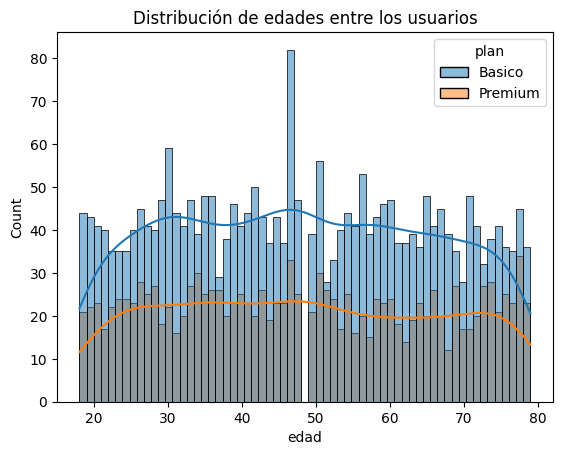

In [30]:
# Histograma para visualizar la edad (age)
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data = user_profile, x = "age", hue = "plan", bins = 63, color = "red", kde = True)
plt.xlabel("edad")
plt.title("Distribución de edades entre los usuarios")
plt.show()

💡Insights: 
- Distribución simétrica bastante pareja con un pico a los 46 años y un valle sin regisros a los 49.
- Hay otros picos para las edades de 30 y 75 años.

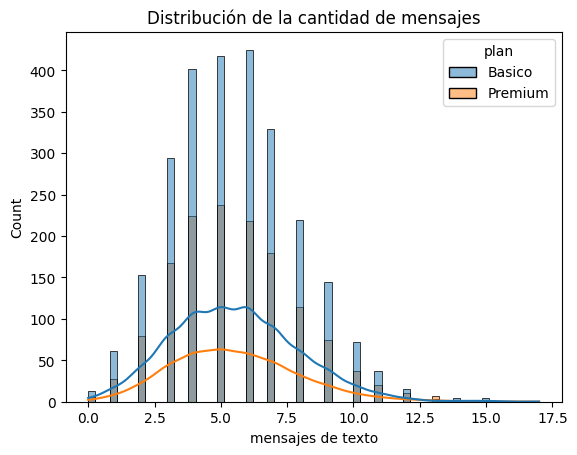

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data = user_profile, x = "cant_mensajes", hue = "plan", bins = 63, color = "green", kde = True)
plt.xlabel("mensajes de texto")
plt.title("Distribución de la cantidad de mensajes")
plt.show()

💡Insights: 
- Distribución sesgada a la derecha que representa una minoría de clientes que envía muchos más mensajes que el promedio.

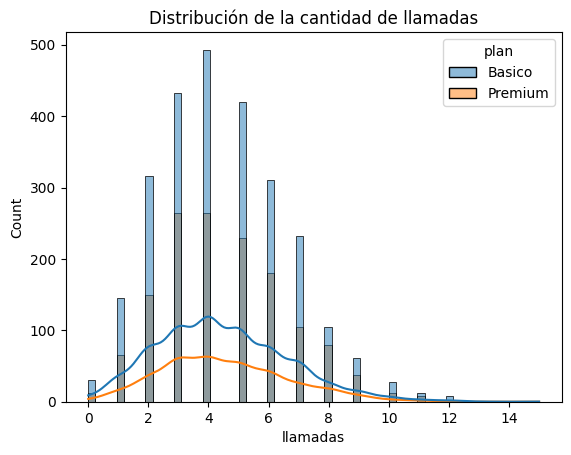

In [32]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data = user_profile, x = "cant_llamadas", hue = "plan", bins = 63, color = "blue", kde = True)
plt.xlabel("llamadas")
plt.title("Distribución de la cantidad de llamadas")
plt.show()


💡Insights: 
- Distribución normal con sesgo a la derecha que representa una minoría de usuarios que hace más llamadas de lo normal.

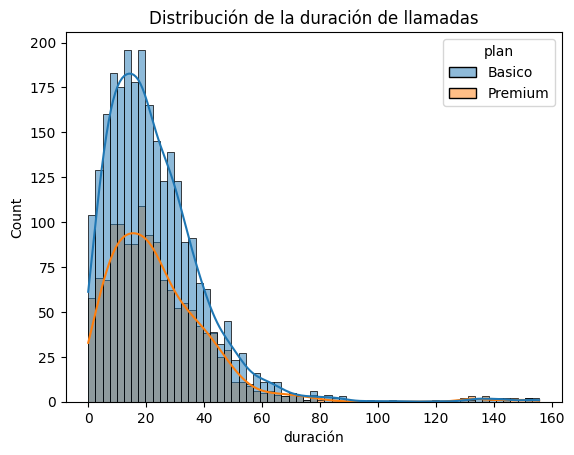

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile, x = "cant_minutos_llamada", hue = "plan", bins = 63, color = "red", kde = True)
plt.xlabel("duración")
plt.title("Distribución de la duración de llamadas")
plt.show()


💡Insights: 
- Distribución normal con sesgo a la derecha que representa una minoría de usuarios que hacen llamadas más largas de lo normal.
- La diferencia entre la mayoría de registros y la cola es mucho más pronunciada que en otras características.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

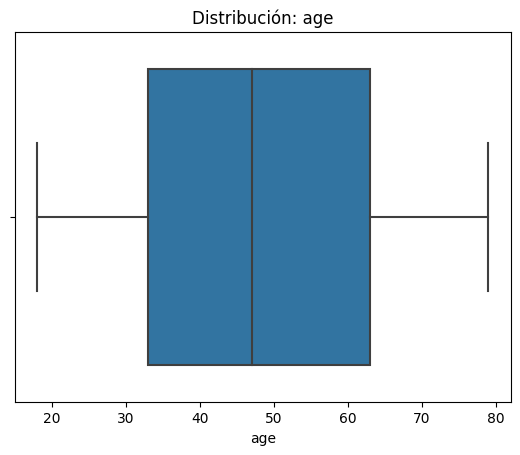

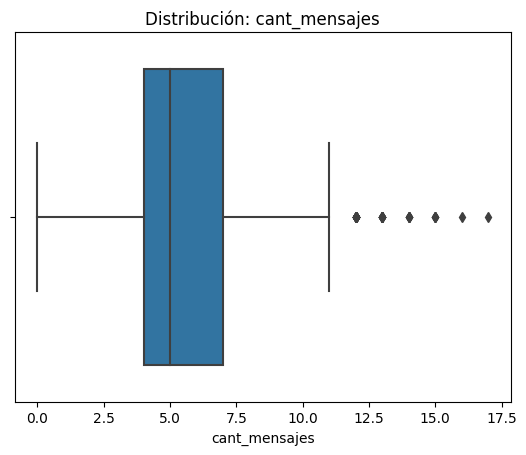

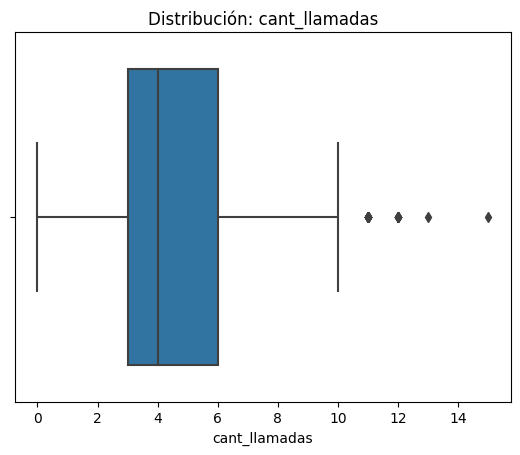

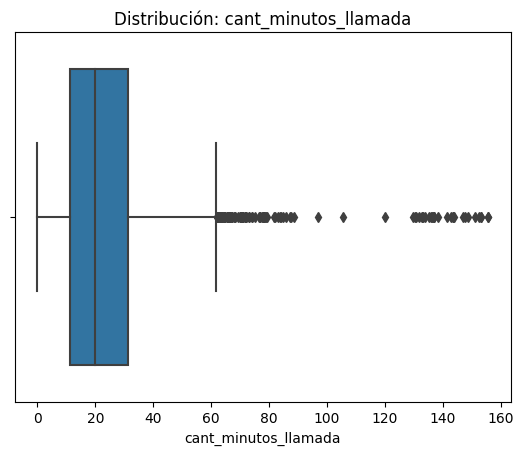

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data = user_profile, x = col)
    plt.title(f"Distribución: {col}")
    plt.show()

In [35]:


# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
Q1 = {}
Q3 = {}
IQR = {}
Lim_Min = {}
Lim_Max = {}
se_pasa = {}
se_pasa_pct = {}
for col in columnas_limites:
    Q1[col] = user_profile[col].quantile(0.25)
    Q3[col] = user_profile[col].quantile(0.75)
    IQR[col] = Q3[col] - Q1[col]
    Lim_Min[col] = Q1[col] - 1.5*IQR[col]
    Lim_Max[col] = Q3[col] + 1.5*IQR[col]
    se_pasa[col] = len(user_profile[user_profile[col] > Lim_Max[col]])
    se_pasa_pct[col] = se_pasa[col]*100/4000

print("Q1")
print(Q1)
print("Q3")
print(Q3)
print("IQR")
print(IQR)
print("Limite inferior")
print(Lim_Min)
print("Limite superior")
print(Lim_Max)
print("outliers que pasan el límite superior")
print(se_pasa)
print("outliers que pasan el límite superior (%)")
print(se_pasa_pct)

Q1
{'age': 33.0, 'cant_mensajes': 4.0, 'cant_llamadas': 3.0, 'cant_minutos_llamada': 11.1075}
Q3
{'age': 63.0, 'cant_mensajes': 7.0, 'cant_llamadas': 6.0, 'cant_minutos_llamada': 31.4125}
IQR
{'age': 30.0, 'cant_mensajes': 3.0, 'cant_llamadas': 3.0, 'cant_minutos_llamada': 20.305}
Limite inferior
{'age': -12.0, 'cant_mensajes': -0.5, 'cant_llamadas': -1.5, 'cant_minutos_llamada': -19.35}
Limite superior
{'age': 108.0, 'cant_mensajes': 11.5, 'cant_llamadas': 10.5, 'cant_minutos_llamada': 61.870000000000005}
outliers que pasan el límite superior
{'age': 0, 'cant_mensajes': 46, 'cant_llamadas': 30, 'cant_minutos_llamada': 109}
outliers que pasan el límite superior (%)
{'age': 0.0, 'cant_mensajes': 1.15, 'cant_llamadas': 0.75, 'cant_minutos_llamada': 2.725}


In [36]:

user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.122250,5.523000,4.477000,23.311225
std,17.690408,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [37]:
user_profile[user_profile["cant_minutos_llamada"] == 2028]

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
# En cant_mensajes se presenta un límite muy cercano al máximo definido por el método IQR, reforzando la condición de que son comportamiento naturales por parte de susuarios intensivos, como infirió a partir de la inspección visual de los datos. Se mantendrán los outliers sin capearlos ya que su efecto sobre el promedio es reducido.
- cant_llamadas: mantener o no outliers, porqué?
# El máximo del dataset y el límite calculado con IQR son bastante cercanos, lo cual también se vió reflejado en el histograma y boxplot. Dado que éstos outliers representan el comportamiento natural de usuarios, se deben mantener; pues su efecto sobre la media no es de gran magnitud.
- cant_minutos_llamada: mantener o no outliers, porqué?
# Los outliers en esta columna deben eliminarse ya que corresponden a más de tres veces el límite establecido por el IQR, lo cual EN CONJUNCIÓN CON EL ANÁLISIS GRÁFICO nos muestra que no corresponden a comportamientos naturales del usuario. 

# Se consideró la posibilidad de que correspondieran a datos de clientes corporativos pero se descarta al analizar de forma particular los registros que presentan estas duraciones de llamadas extremas; concluyéndose que corresponden a errores de captura.

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Los histogramas y boxplots están construidos, y el cálculo de Q1, Q3, IQR y límites está presente. Sin embargo, esta sección debe rehacerse después de corregir <code>cant_minutos_llamada</code>, porque actualmente esa variable contiene la suma de <code>length</code> y no de <code>duration</code>.<br><br>
Además, los histogramas deben permitir comparar los planes Básico y Premium. Actualmente graficas cada variable sin separar por <code>plan</code>.<br><br>
Para corregirlo:<br>
1. Reconstruye primero las métricas del perfil de usuario.<br>
2. Genera nuevamente los cuatro histogramas usando el plan como variable de comparación.<br>
3. Recalcula los boxplots e IQR sobre las variables corregidas.<br>
4. Actualiza las conclusiones sobre outliers. No elimines un valor solo porque sea varias veces mayor al límite IQR; primero debes justificar si realmente es un error de captura o un comportamiento extremo válido.<br>
5. Como mejora, reporta también cantidad y porcentaje de outliers.
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [38]:
# Crear columna grupo_uso
def Grupos_uso(row):
    Calls = row["cant_llamadas"]
    Texts = row["cant_mensajes"]
    if pd.isna(Calls) or pd.isna(Texts):
        return "Error en registro"
    if Calls < 5 and Texts < 5:
        return "Bajo Uso"
    elif Calls < 10 and Texts < 10:
        return "Uso Medio"
    else:
        return "Alto uso"
    
user_profile["grupo_uso"] = user_profile.apply(Grupos_uso, axis = 1)
user_profile[["cant_llamadas", "cant_mensajes", "grupo_uso"]]

,cant_llamadas,cant_mensajes,grupo_uso
0,3.0,7.0,Uso Medio
1,10.0,5.0,Alto uso
2,2.0,5.0,Uso Medio
3,3.0,11.0,Alto uso
4,3.0,4.0,Bajo Uso
...,...,...,...
3995,3.0,6.0,Uso Medio
3996,3.0,4.0,Bajo Uso
3997,3.0,5.0,Uso Medio
3998,6.0,6.0,Uso Medio


In [39]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso Medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso Medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo Uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [40]:
# Crear columna grupo_edad
def Grupos_edad(row):
    Age = row["age"]
    if pd.isna(Age):
        return "Error en registro"
    if Age < 30:
        return "Joven"
    elif Age < 60:
        return "Adulto"
    else:
        return "Adulto mayor"
    
user_profile["grupo_edad"] = user_profile.apply(Grupos_edad, axis = 1)
user_profile[["age", "grupo_edad"]]

,age,grupo_edad
0,38.0,Adulto
1,53.0,Adulto
2,57.0,Adulto
3,69.0,Adulto mayor
4,63.0,Adulto mayor
...,...,...
3995,60.0,Adulto mayor
3996,24.0,Joven
3997,58.0,Adulto
3998,57.0,Adulto


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso Medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso Medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo Uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

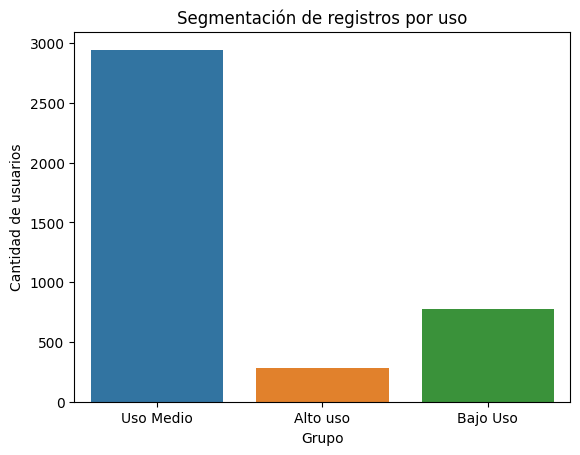

In [42]:

# Visualización de los segmentos por uso
sns.countplot(data = user_profile, x= user_profile["grupo_uso"])

plt.xlabel("Grupo")
plt.ylabel("Cantidad de usuarios")
plt.title("Segmentación de registros por uso")
plt.show()





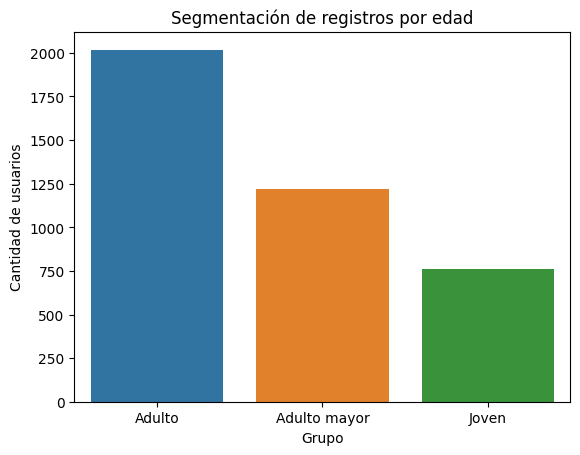

In [43]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, x= user_profile["grupo_edad"])
plt.xlabel("Grupo")
plt.ylabel("Cantidad de usuarios")
plt.title("Segmentación de registros por edad")

plt.show()

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
Las reglas de edad están correctamente implementadas y la lógica principal de uso respeta los umbrales solicitados. Es una buena práctica que hayas detectado explícitamente los registros con métricas nulas.<br><br>
Como mejora, después de reconstruir el perfil por usuario revisa el caso sin actividad. Si no tiene llamadas ni mensajes observados, sus métricas pueden representarse como 0 antes de segmentar, de modo que quede clasificado según las mismas reglas de Bajo/Medio/Alto uso y no aparezca una categoría adicional <code>Error en registro</code>.
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Valores nulos y estructurales: El análisis de nulos reveló patrones esperados. En usage, los nulos en "duration" (55.19%) y "length" (44.74%) no son errores, sino que son estructurales: duration solo existe para llamadas (call) y length solo para mensajes (text). Se deben conservar y no imputar.
- Presencia de valores sentinela en la columna "age" de la base "users".


🔍 **Segmentos por Edad**
- La población se segmenta en tres grupos: Joven (<30), Adulto (30-59) y Adulto Mayor (>=60). El grupo de Adultos es el más numeroso, con 2,343 usuarios (58.6%), seguido por los Adultos Mayores con 1,157 (28.9%) y los Jóvenes con 500 (12.5%). La distribución es relativamente pareja, sin picos anómalos que sugieran errores de captura.


📊 **Segmentos por Nivel de Uso**
- La mayoría de los registros se concentran en la categoría de "uso medio" (entre 5 y 10 llamadas y textos en el periodo), reflejando una distribución cercana a la normal.
- Las cantidades de llamadas y mensajes presentan outliers que parecen ser comportamientos naturales de usuarios intensivos. Se recomienda mantenerlos, ya que su impacto en las métricas generales es limitado (1.15% para mensajes, 0.75% para llamadas)
- Los outliers presentados marcan un sesgo a la derecha de los datos que se puede explicar con comportamientos naturales de los usuarios (uso intensivo del teléfono).
- La variable cant_minutos_llamada (correctamente calculada con duration) reveló outliers más extremos. Un usuario, por ejemplo, acumuló 2,028 minutos de llamadas, un valor muy superior al límite superior del IQR (61.87 minutos). Estos podrían indicar errores de captura o planes corporativos, por lo que se recomienda investigar estos casos antes de un análisis más profundo.


➡️ Esto sugiere que aunque el comportamiento demostrado por la cantidad de usos presenta un patrón natural, los registros de duración de llamadas muestran un grupo de outliers que no representan comportamientos posibles y se deben tratar antes de procesarse para prevenir distorsiones en las conclusiones derivadas de su análisis. La calidad de los datos puede ser aceptable para un análisis de la situación, pero los problemas de calidad deben resolverse para obtener isnights más certeros. Los datos, una vez tratados, son aptos para el análisis. Mientras que el uso (cantidad de llamadas/mensajes) sigue patrones de consumo natural, la duración de las llamadas contiene valores atípicos que deben ser investigados para no distorsionar las conclusiones del negocio.


💡 **Recomendaciones**

- Plan Premium: Dado que los usuarios de este plan realizan más llamadas y envían más mensajes, se recomienda enfocar las campañas de up-selling hacia los usuarios de "Uso Medio" del plan Básico, destacando los mayores límites del plan Premium.

- Investigación de Datos: Se recomienda investigar el origen de los minutos de llamada extremos para determinar si son errores o clientes corporativos. Si son errores, deben corregirse; si son clientes válidos, se podría diseñar un plan corporativo o de alto consumo.

- Segmentación Demográfica: El segmento de Adultos es el núcleo del negocio. Las estrategias de retención deben enfocarse en este grupo, quizás con ofertas de servicios adicionales (como datos para streaming), mientras que se puede explorar el potencial del segmento Joven con planes más flexibles y orientados a redes sociales.


<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
El análisis ejecutivo contiene varias conclusiones que dependen de resultados que deben corregirse antes.<br><br>
Por ejemplo, indicas que existen “4.000 registros nulos = 12.5%”, pero ese resultado proviene del conteo incorrecto de nulos. También concluyes que los minutos extremos corresponden a errores de captura, aunque la métrica de minutos está construida actualmente con <code>length</code>.<br><br>
Después de corregir las secciones anteriores:<br>
1. Actualiza las cifras de calidad de datos.<br>
2. Incluye cantidades o porcentajes de los segmentos por edad y uso.<br>
3. Actualiza los outliers usando los minutos de llamada reales.<br>
4. Separa claramente lo observado de las hipótesis que recomendarías investigar.<br>
5. Conecta cada recomendación con un hallazgo cuantificado del análisis.
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

https://github.com/TESoCo/telecom-analysis

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
El repositorio de GitHub cumple: es público, contiene el notebook y tiene un <code>README.md</code> completo con descripción, datasets, etapas y guía de reproducción.<br><br>
Sin embargo, el notebook no es reproducible de principio a fin porque la última celda es una <b>celda de código</b> que contiene únicamente la URL del repositorio. Al ejecutarla se produce un <code>SyntaxError</code>.<br><br>
Para corregirlo:<br>
1. Elimina la celda de código que contiene la URL.<br>
2. Reemplaza en la celda Markdown anterior <code>LINK a tu repo aquí</code> por la URL real del repositorio.<br>
3. Ejecuta <b>Restart & Run All</b> desde el inicio.<br>
4. Confirma que el notebook llegue al final sin errores.<br>
5. Sube a GitHub esa misma versión final corregida.
</div>